In [1]:
# Library imports

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

Decisional Tree

In [2]:
# Data creation

df = pd.DataFrame({
    "temperature": [400, 450, 500, 550, 500, 550, 600, 600, 650, 700],
    "time": [1, 1, 1, 1, 2, 2, 1, 2, 2, 2],
    "luminescence": [
        "Low", "Low", "High", "High",
        "High", "High", "High", "High", "Low", "Low"
    ]
})


X = df[["temperature", "time"]]
y = df["luminescence"]

In [3]:
df # Display the dataframe to check if it has been created correctly.

,temperature,time,luminescence
0,400,1,Low
1,450,1,Low
2,500,1,High
3,550,1,High
4,500,2,High
5,550,2,High
6,600,1,High
7,600,2,High
8,650,2,Low
9,700,2,Low


In [4]:
X # Display the features (temperature and time) to verify that they have been created correctly.

,temperature,time
0,400,1
1,450,1
2,500,1
3,550,1
4,500,2
5,550,2
6,600,1
7,600,2
8,650,2
9,700,2


In [5]:
y   #

0     Low
1     Low
2    High
3    High
4    High
5    High
6    High
7    High
8     Low
9     Low
Name: luminescence, dtype: str

In [6]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

Tree = DecisionTreeClassifier(
    max_depth=2,           # Depth of the tree.
    random_state=42      # Set the random state for reproducibility
)

Tree.fit(X, y)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at 

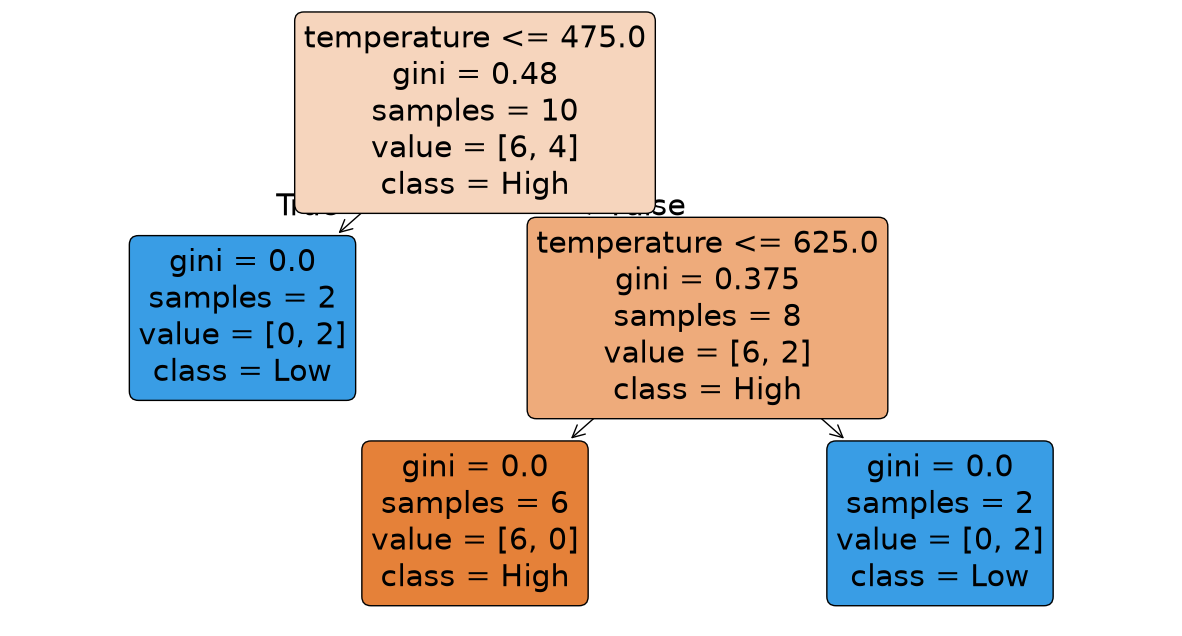

In [7]:
plt.figure(figsize=(15, 8))
plot_tree(
    Tree,
    feature_names=["temperature", "time"],
    class_names=Tree.classes_,
    filled=True,
    rounded=True
)
plt.show()

In [8]:
new_synthesis = pd.DataFrame({
    "temperature": [525],
    "time": [2]
})

prediction = Tree.predict(new_synthesis)

print("Predicted luminescence :", prediction[0])

Predicted luminescence : High


RandomForest

In [9]:
# Data import        /!\ Change the file name /!\ For Google Colab Users: "Luminescence.csv",sep=";"

df = pd.read_csv("Luminescence.csv",sep=";")  #df = dataframe. sep is here to explain that the separator is a semicolon, not a comma. This is important for reading the CSV file correctly.

df # Display the dataframe to check if it has been imported correctly. This is important for verifying that the data has been read correctly and is in the expected format.

,temperature,time,luminescence
0,400,1,20
1,450,1,35
2,500,1,65
3,550,1,90
4,500,2,80
5,550,2,110
6,600,1,70
7,600,2,75
8,650,2,30
9,700,2,15


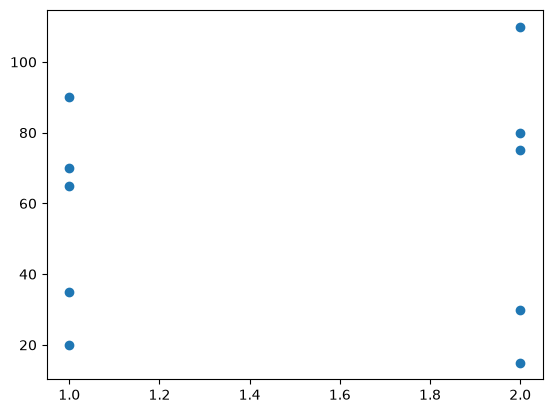

In [10]:
plt.scatter(df["time"],df["luminescence"])  #plt.scatter instead of plt.plot because we want to create a scatter plot, not a line plot. This is important for visualizing the relationship between the two variables.

plt.show() # Display the plot

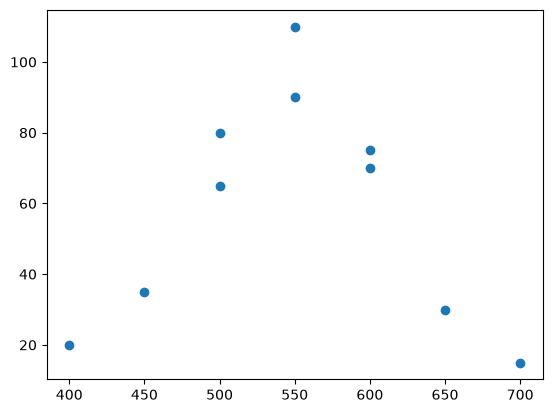

In [11]:
plt.scatter(
    df["temperature"],
    df["luminescence"])  #plt.scatter instead of plt.plot because we want to create a scatter plot, not a line plot. This is important for visualizing the relationship between the two variables.

plt.show() # Display the plot

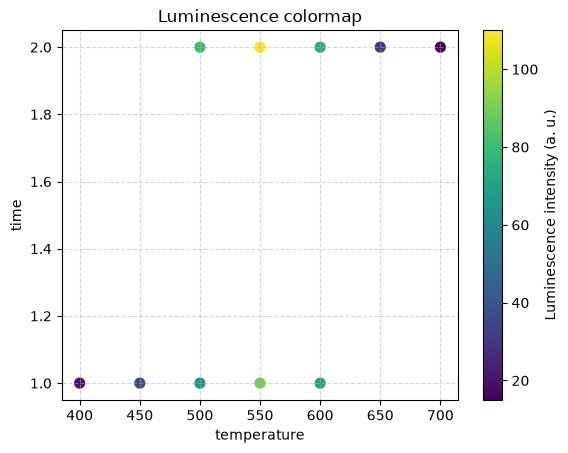

In [12]:
# 3D graph

graph = plt.scatter(
    df["temperature"],
    df["time"],
    c=df["luminescence"],  # Use the 'luminescence' column to determine the color of each point in the scatter plot
    cmap='viridis',         # Use the 'viridis' colormap for better visualization of the luminescence intensity
    s=50)                   #Size of the points

#Caption
colorbar = plt.colorbar(graph)
colorbar.set_label("Luminescence intensity (a. u.)")  # Set the label for the colorbar


plt.title("Luminescence colormap")
plt.xlabel("temperature")
plt.ylabel("time")
plt.grid(True, linestyle="--", alpha=0.5)

plt.show() # Display the plot

In [13]:
# Let's make our first RF! Let's define the features and the target variable. The features are the columns that we will use to predict the target variable. In this case, we will use "temperature" and "time" as features to predict "luminescence".

X = df[["temperature", "time"]]
y = df["luminescence"]

# We want to understand the relationship y = f(X) where f is a function that we will try to learn using a machine learning model. In this case, we will use a Random Forest Classifier to learn the function f.

In [14]:
# Verify the shapes of the features and target variable. This is important for ensuring that the data is in the correct format for training the model.
X

,temperature,time
0,400,1
1,450,1
2,500,1
3,550,1
4,500,2
5,550,2
6,600,1
7,600,2
8,650,2
9,700,2


In [15]:
# Verify the shapes of the features and target variable. This is important for ensuring that the data is in the correct format for training the model.
y

0     20
1     35
2     65
3     90
4     80
5    110
6     70
7     75
8     30
9     15
Name: luminescence, dtype: int64

In [16]:
# Let's try to predict the luminescence intensity based on temperature and time using a machine learning model. We will use a Random Forest Classifier for this purpose.
from sklearn.ensemble import RandomForestClassifier
clf = RandomForestClassifier(n_estimators=100) #100 means 100 trees

In [17]:
# Define the data to train the model and to test it. Usually 80 % train and 20 % test

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

In [18]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape # Verify the shapes of the training and testing datasets. This is important for ensuring that the data has been split correctly and that the model will be trained and tested on the appropriate subsets of the data.

((8, 2), (2, 2), (8,), (2,))

In [19]:
X_train

,temperature,time
4,500,2
1,450,1
8,650,2
3,550,1
0,400,1
5,550,2
9,700,2
6,600,1


In [20]:
X_test

,temperature,time
2,500,1
7,600,2


In [21]:
y_train

4     80
1     35
8     30
3     90
0     20
5    110
9     15
6     70
Name: luminescence, dtype: int64

In [22]:
y_test

2    65
7    75
Name: luminescence, dtype: int64

In [23]:
# Train the Random Forest Classifier

clf.fit(X_train, y_train);

In [24]:
# Save the predictions of the model on the test set to a variable called y_preds. This is important for evaluating the performance of the model on unseen data.

y_preds = clf.predict(X_test)
y_preds

array([ 35, 110])

In [25]:
# Comparison with the real values of the test set. This is important for evaluating the performance of the model and understanding how well it generalizes to unseen data. 1=100% correct prediction, 0=wrong prediction

clf.score(X_train, y_train)

1.0

In [26]:
clf.score(X_test, y_test)

0.0

Why do we have this results?

In [27]:
# Let's try once again:

from sklearn.ensemble import RandomForestClassifier
clf = RandomForestClassifier(n_estimators=10, random_state=42) #10 means 10 trees, random_state is set for reproducibility

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42) # Set the random state for reproducibility

clf.fit(X_train, y_train);

clf.score(X_train, y_train)

clf.score(X_test, y_test)

0.0

We can tune the number of hyperparameters: number of trees

In [28]:
# random seed to ensure reproducibility of results. This is important for ensuring that the results of the model can be replicated and verified by others.

np.random.seed(42)

for i in range(1, 10, 1):
    print(f"Trying model with {i} estimators...")
    clf = RandomForestClassifier(n_estimators=i).fit(X_train, y_train)
    print(f"Model accuracy on train set: {clf.score(X_train, y_train) * 100:.2f}%")
    print(f"Model accuracy on test set: {clf.score(X_test, y_test) * 100:.2f}%")
    print("")

Trying model with 1 estimators...
Model accuracy on train set: 62.50%
Model accuracy on test set: 0.00%

Trying model with 2 estimators...
Model accuracy on train set: 62.50%
Model accuracy on test set: 0.00%

Trying model with 3 estimators...
Model accuracy on train set: 75.00%
Model accuracy on test set: 0.00%

Trying model with 4 estimators...
Model accuracy on train set: 87.50%
Model accuracy on test set: 0.00%

Trying model with 5 estimators...
Model accuracy on train set: 100.00%
Model accuracy on test set: 0.00%

Trying model with 6 estimators...
Model accuracy on train set: 100.00%
Model accuracy on test set: 0.00%

Trying model with 7 estimators...
Model accuracy on train set: 75.00%
Model accuracy on test set: 0.00%

Trying model with 8 estimators...
Model accuracy on train set: 100.00%
Model accuracy on test set: 0.00%

Trying model with 9 estimators...
Model accuracy on train set: 87.50%
Model accuracy on test set: 0.00%



In [29]:
# Prediction of a new experiment: use the RandomForest with new experimental parameters (time and temperature) and predict the luminescence

new_exp = pd.DataFrame({
    "temperature": [515],
    "time": [1.5]
})

prediction = clf.predict(new_exp)

print("Predicted luminescence :", prediction[0])

Predicted luminescence : 65


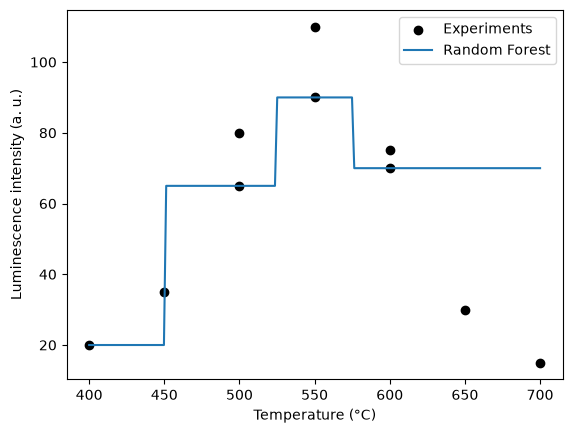

In [30]:
# Let's plot several predictions for new experiments with a time of 1.5 h.

temperatures = np.linspace(400, 700, 200)  # Creation of 100 temperatures between 400 and 700

X_test = pd.DataFrame({
    "temperature": temperatures,
    "time": 1.5
})

y_pred = clf.predict(X_test)


# Plot the real experiments
plt.scatter(df["temperature"], df["luminescence"],
            label="Experiments", color="black")

# Plot the predicted values
plt.plot(temperatures, y_pred,
         label="Random Forest")

# Captions
plt.xlabel("Temperature (°C)")
plt.ylabel("Luminescence intensity (a. u.)")
plt.legend()
plt.show()

Real Database
1. Plot the intensity in function of the different parameters. This is important for visualizing the relationships between the different parameters and the luminescence intensity.
2. Plot the initial phase space: how to represent vast phase spaces?
3. Try to predict the luminescence intensity in function of the different numerical parameters using a RF.

In [39]:
# Data import      /!\ Change the file name /!\ For Google Colab Users: "DB_ML_supercomp_papier.csv",sep=";"

df = pd.read_csv("DB_ML_supercomp_papier.csv",sep=";")

df

,ID,Eu%,Laser power(%),Laser speed(%),z,beamsize(mm),lum_int_norm_updated,energy (J),Phase1,Phase_1_simple,Confidence1,Weight fraction1,line density (trait/cm)
0,1,0,25.0,0.08,20,0.00366,502.376685,4.274534e+06,LaPO4,Monazite,76,1.0,1.0
1,2,0,10.0,1.03,0,0.00005,572.706105,1.749787e+07,Unknown phase,Unknown phase,61,1.0,1.8
2,3,0,75.5,14.92,20,0.00366,510.018270,6.921766e+04,LaPO4,Monazite,87,0.9,1.0
3,4,0,14.5,0.49,20,0.00366,545.780668,4.047722e+05,No phase,No phase,0,0.0,1.0
4,5,0,28.0,5.76,20,0.00366,540.664015,6.649275e+04,Unknown phase,Unknown phase,45,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
475,116,80,15.5,0.07,20,0.00366,4082.289579,3.028813e+06,EuPO4,Monazite,84,1.0,1.0
476,117,80,15.6,0.03,20,0.00366,6738.342240,7.112825e+06,EuPO4,Monazite,56,1.0,1.0
477,118,85,10.6,0.02,20,0.00366,9541.931220,7.249610e+06,EuPO4,Monazite,93,1.0,1.0
478,119,85,11.9,0.02,20,0.00366,9430.425767,8.138713e+06,EuPO4,Monazite,61,1.0,1.0


In [40]:
print(list(df.columns[:17]))

['ID', 'Eu%', 'Laser power(%)', 'Laser speed(%)', 'z', 'beamsize(mm)', 'lum_int_norm_updated', 'energy (J)', 'Phase1', 'Phase_1_simple', 'Confidence1', 'Weight fraction1', 'line density (trait/cm)']


In [41]:
df = df.drop(columns=["Confidence1", "Weight fraction1", "Phase1", "Phase_1_simple"])

In [42]:
df

,ID,Eu%,Laser power(%),Laser speed(%),z,beamsize(mm),lum_int_norm_updated,energy (J),line density (trait/cm)
0,1,0,25.0,0.08,20,0.00366,502.376685,4.274534e+06,1.0
1,2,0,10.0,1.03,0,0.00005,572.706105,1.749787e+07,1.8
2,3,0,75.5,14.92,20,0.00366,510.018270,6.921766e+04,1.0
3,4,0,14.5,0.49,20,0.00366,545.780668,4.047722e+05,1.0
4,5,0,28.0,5.76,20,0.00366,540.664015,6.649275e+04,1.0
...,...,...,...,...,...,...,...,...,...
475,116,80,15.5,0.07,20,0.00366,4082.289579,3.028813e+06,1.0
476,117,80,15.6,0.03,20,0.00366,6738.342240,7.112825e+06,1.0
477,118,85,10.6,0.02,20,0.00366,9541.931220,7.249610e+06,1.0
478,119,85,11.9,0.02,20,0.00366,9430.425767,8.138713e+06,1.0


## 1. Plotting the data

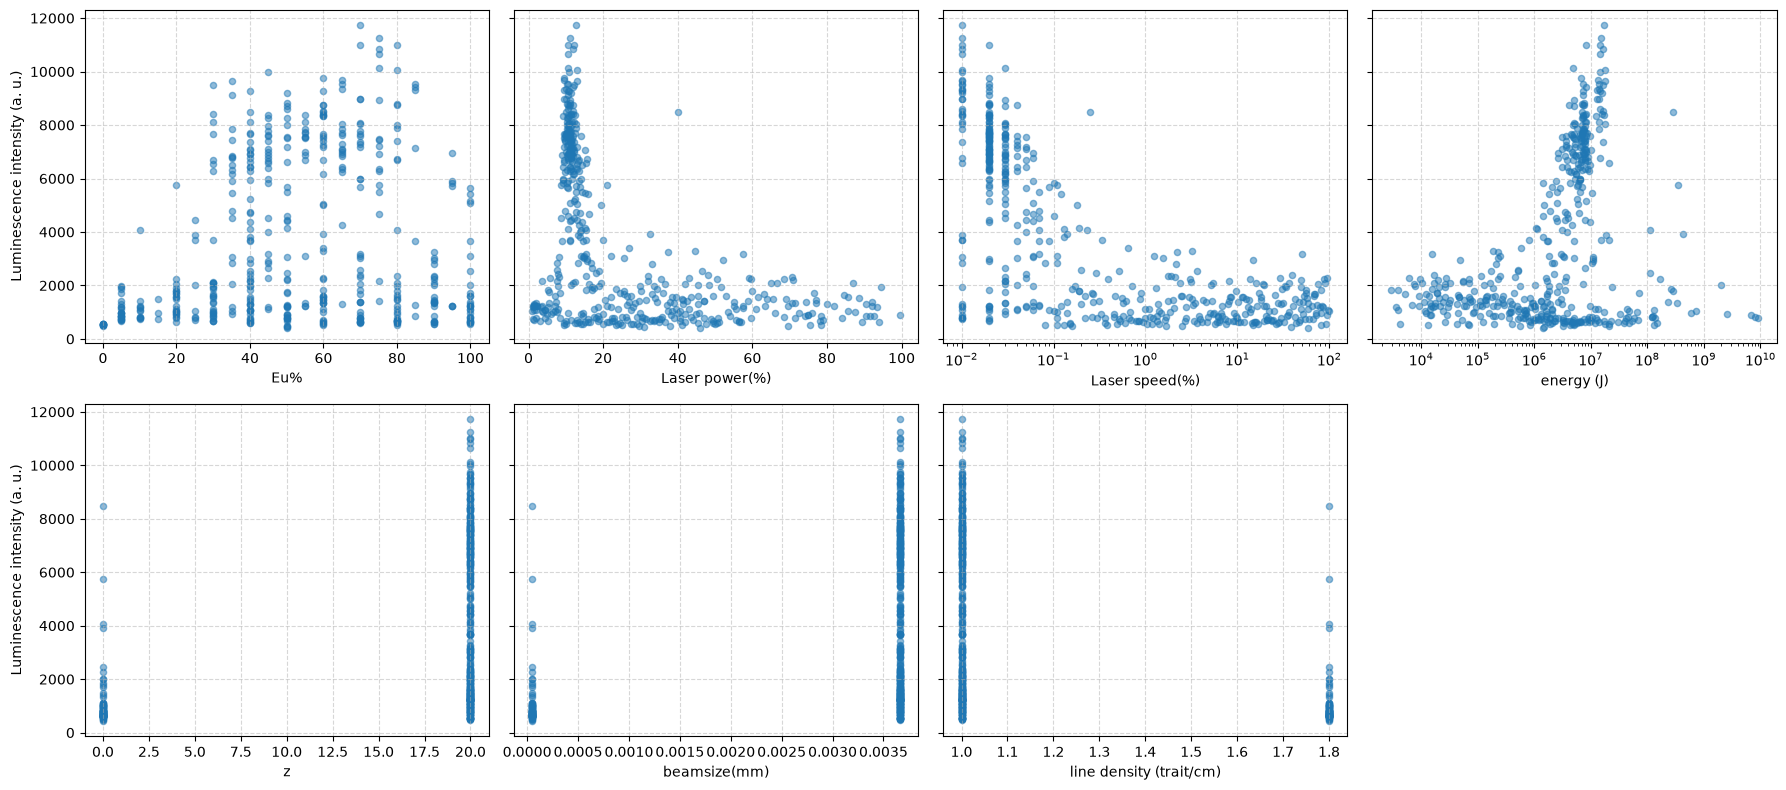

In [ ]:
target = "lum_int_norm_updated"   # Luminescence intensity (normalized). This is the value we want to understand and later predict.

parameters = [                    # The synthesis parameters (ID, phase, confidence and weight fraction are not synthesis parameters)
    "Eu%",
    "Laser power(%)",
    "Laser speed(%)",
    "energy (J)",
    "z",
    "beamsize(mm)",
    "line density (trait/cm)",
]

log_parameters = ["Laser speed(%)", "energy (J)"]   # These values cover several orders of magnitude: a log scale spreads the points out.

fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharey=True)   # 2 rows x 4 columns of plots, all sharing the same y axis
axes = axes.flatten()                                           # Turn the 2x4 grid into a simple list of 8 plots

for ax, parameter in zip(axes, parameters):
    ax.scatter(df[parameter], df[target], alpha=0.5, s=20)    
    if parameter in log_parameters:
        ax.set_xscale("log")
    ax.set_xlabel(parameter)
    ax.grid(True, linestyle="--", alpha=0.5)

axes[0].set_ylabel("Luminescence intensity (a. u.)")
axes[4].set_ylabel("Luminescence intensity (a. u.)")
axes[-1].axis("off")             


plt.tight_layout()
plt.show()

## 2. Phase space

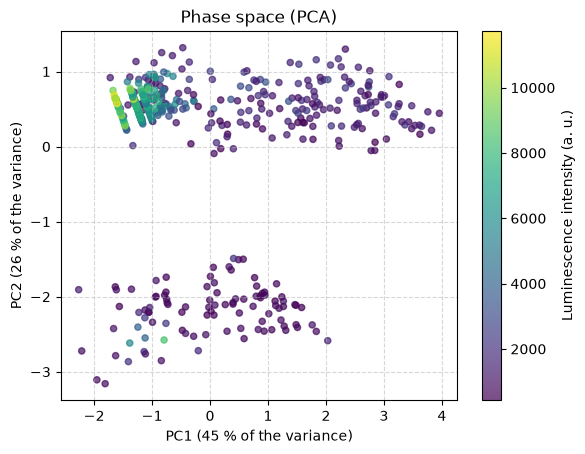

In [43]:
# PCA (Principal Component Analysis): squeeze the synthesis parameters into 2 new axes (PC1, PC2) that keep as much of the spread of the data as possible.
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X_phase = df[["Eu%", "Laser power(%)", "Laser speed(%)", "energy (J)", "z"]].copy()   # z only: beamsize and line density carry exactly the same information
X_phase["Laser speed(%)"] = np.log10(X_phase["Laser speed(%)"])                         # log10 because these values cover several orders of magnitude
X_phase["energy (J)"] = np.log10(X_phase["energy (J)"])

X_scaled = StandardScaler().fit_transform(X_phase)   # Put every parameter on the same scale (mean 0, std 1), otherwise the parameters with the biggest numbers dominate the PCA

pca = PCA(n_components=2)                            # Keep 2 components to be able to plot them
X_pca = pca.fit_transform(X_scaled)

graph = plt.scatter(X_pca[:, 0], X_pca[:, 1],
                    c=df[target],                    # Color = luminescence intensity
                    cmap="viridis", s=20, alpha=0.7)

colorbar = plt.colorbar(graph)
colorbar.set_label("Luminescence intensity (a. u.)")

plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.0f} % of the variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.0f} % of the variance)")
plt.title("Phase space (PCA)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [ ]:
# What do PC1 and PC2 mean? Each number shows how much a parameter contributes to the new axis (sign = direction).
pd.DataFrame(pca.components_, columns=X_phase.columns, index=["PC1", "PC2"]).round(2)